In [1]:
import os, warnings
from pathlib import Path
if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)  # run from the project root so data/ paths resolve
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from cifresignificative.analysis.data import *
from cifresignificative.viz.style import *
apply_style()
panel = load_panel()


# 23 - Growth accounting by industry (EU KLEMS & INTANProd)
Labour productivity per hour growth split into contributions of total factor productivity (TFP), labour composition (skills, experience), ICT capital, other tangible capital and intangible capital, for the market economy and by industry, 1996-2019 (EU KLEMS release 2025). Contributions are in percentage points per year. Notebooks 08 and 13 showed *where* Italy's productivity lags; this shows *what kind* of growth is missing.

1996-2019


variable,LP1ConIntang,LP1ConLC,LP1ConTFP,LP1ConTangICT,LP1ConTangNICT,LP1TFP_I,LP1_G
iso3,,,,,,,
ITA,0.25,0.36,-0.36,0.04,0.30,105.46,0.60
DEU,0.28,0.11,0.85,-0.01,0.21,95.26,1.45
FRA,0.39,0.48,0.19,0.01,0.24,100.95,1.32
ESP,0.28,0.34,-0.54,0.02,0.47,104.51,0.57
median of other EU27,0.35,0.36,0.79,0.02,0.22,100.00,2.35


1996-2007


variable,LP1ConIntang,LP1ConLC,LP1ConTFP,LP1ConTangICT,LP1ConTangNICT,LP1TFP_I,LP1_G
iso3,,,,,,,
ITA,0.23,0.24,-0.22,0.06,0.47,109.45,0.78
DEU,0.24,-0.07,1.42,0.01,0.30,91.27,1.90
FRA,0.31,0.32,0.97,0.02,0.36,101.33,1.97
ESP,0.19,0.13,-0.75,0.02,0.44,108.56,0.03
median of other EU27,0.40,0.32,1.37,0.02,0.30,92.39,3.34


2008-2019


variable,LP1ConIntang,LP1ConLC,LP1ConTFP,LP1ConTangICT,LP1ConTangNICT,LP1TFP_I,LP1_G
iso3,,,,,,,
ITA,0.27,0.48,-0.49,0.02,0.13,101.47,0.41
DEU,0.31,0.30,0.28,-0.03,0.13,99.26,0.99
FRA,0.47,0.65,-0.58,0.01,0.12,100.57,0.67
ESP,0.37,0.55,-0.33,0.02,0.50,100.46,1.10
median of other EU27,0.35,0.37,0.21,0.01,0.15,100.00,1.21


countries with market-economy accounts: 30


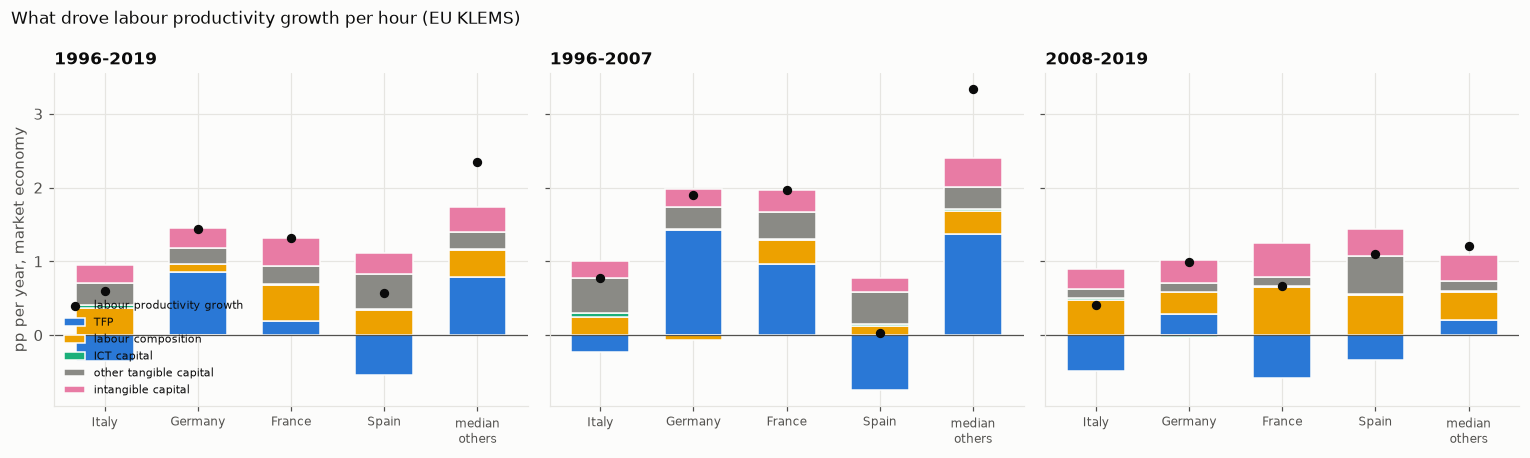

In [2]:
ek = pd.read_parquet(PROCESSED / "euklems_growth.parquet")
def avg(nace, a, b):
    d = ek[(ek.nace_r2_code == nace) & ek.year.between(a, b)]; return d.pivot_table(index="iso3", columns="variable", values="value", aggfunc="mean")
parts = {"LP1ConTFP": "TFP", "LP1ConLC": "labour composition", "LP1ConTangICT": "ICT capital", "LP1ConTangNICT": "other tangible capital", "LP1ConIntang": "intangible capital"}
cols = ["#2a78d6", "#eda100", "#1baf7a", "#8a8a85", "#e87ba4"]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True); summ = {}
for ax, (a, b) in zip(axes, [(1996, 2019), (1996, 2007), (2008, 2019)], strict=True):
    t = avg("MARKT", a, b); oth = t.drop(index=ITALY).loc[[c for c in t.index if c in EU27_ISO3 and c != ITALY]]
    sel = t.loc[[ITALY, "DEU", "FRA", "ESP"]]; sel.loc["median of other EU27"] = oth.median(); sel["LP1_G"] = sel["LP1_G"]
    pos = np.zeros(len(sel)); neg = np.zeros(len(sel))
    for key, col in zip(parts, cols, strict=True):
        v = sel[key].values; base = np.where(v >= 0, pos, neg); ax.bar(range(len(sel)), v, bottom=base, color=col, width=0.62, edgecolor=SURFACE, label=parts[key]); pos += np.where(v >= 0, v, 0); neg += np.where(v < 0, v, 0)
    ax.scatter(range(len(sel)), sel["LP1_G"], color=INK, s=26, zorder=5, label="labour productivity growth"); ax.axhline(0, color=INK2, lw=0.8)
    ax.set_xticks(range(len(sel)), ["Italy", "Germany", "France", "Spain", "median\nothers"], fontsize=8); ax.set_title(f"{a}-{b}"); summ[f"{a}-{b}"] = sel.round(2)
axes[0].set_ylabel("pp per year, market economy"); axes[0].legend(fontsize=7, loc="lower left"); fig.suptitle("What drove labour productivity growth per hour (EU KLEMS)", x=0.01, ha="left", fontsize=11); fig.tight_layout(); save(fig, "23_growth_accounting")
for k, v in summ.items(): print(k); display(v)
print("countries with market-economy accounts:", avg("MARKT", 1996, 2019).LP1_G.notna().sum())

,Italy,median others,n,Italy labour productivity growth,median LP growth
Utilities & waste,-3.78,-1.08,15.0,-1.93,0.50
Construction,-2.01,-0.23,15.0,-1.13,0.54
Professional & admin services,-1.30,-0.15,14.0,-1.70,0.25
Arts & other services,-0.89,-0.55,15.0,-0.08,-0.31
Accommodation & food,-0.86,-0.67,14.0,-0.77,-0.28
Manufacturing,-0.43,1.55,15.0,1.07,3.26
Transport & storage,-0.17,0.46,15.0,0.86,1.32
Mining,0.06,-0.35,14.0,2.85,1.58
Information & communication,0.34,1.15,15.0,1.72,2.60
Agriculture,0.37,1.63,13.0,1.27,3.31


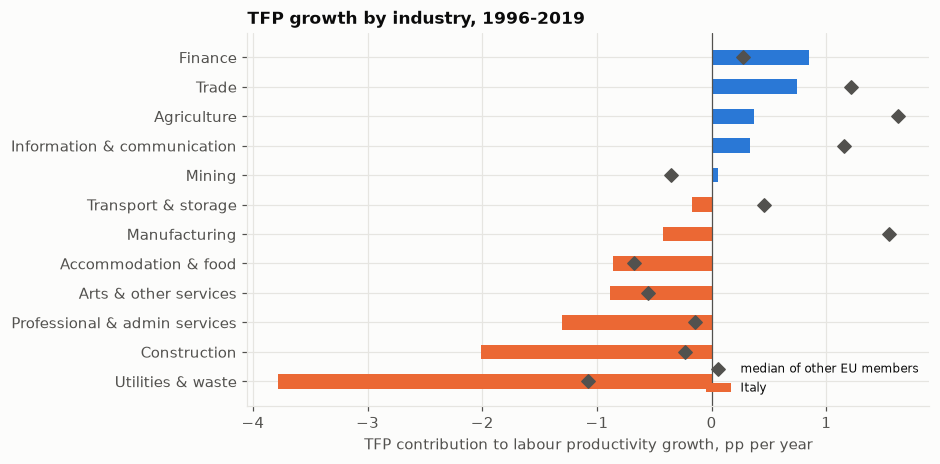

In [3]:
# TFP contribution by industry, 1996-2019: Italy vs the median of the other EU members
secs = {"A": "Agriculture", "B": "Mining", "C": "Manufacturing", "D-E": "Utilities & waste", "F": "Construction", "G": "Trade", "H": "Transport & storage", "I": "Accommodation & food", "J": "Information & communication", "K": "Finance", "M-N": "Professional & admin services", "R-S": "Arts & other services"}
rows = {}
for n, lab in secs.items():
    t = avg(n, 1996, 2019)
    if ITALY in t.index and "LP1ConTFP" in t:
        oth = t.loc[[c for c in t.index if c in EU27_ISO3 and c != ITALY], "LP1ConTFP"].dropna(); rows[lab] = {"Italy": t.loc[ITALY, "LP1ConTFP"], "median others": oth.median(), "n": len(oth), "Italy labour productivity growth": t.loc[ITALY, "LP1_G"], "median LP growth": t.loc[oth.index, "LP1_G"].median()}
tab = pd.DataFrame(rows).T.sort_values("Italy"); display(tab.round(2))
fig, ax = plt.subplots(figsize=(8, 4.4)); yy = np.arange(len(tab))
ax.barh(yy, tab["Italy"], color=[ITALY_C if v >= 0 else EU_C for v in tab["Italy"]], height=0.5, label="Italy"); ax.scatter(tab["median others"], yy, color=INK2, marker="D", s=38, zorder=3, label="median of other EU members")
ax.set_yticks(yy, tab.index); ax.axvline(0, color=INK2, lw=0.8); ax.set_xlabel("TFP contribution to labour productivity growth, pp per year"); ax.set_title("TFP growth by industry, 1996-2019"); ax.legend(fontsize=8, loc="lower right"); save(fig, "23_tfp_by_industry")

TFP 1995-2019: Italy 92 | DEU 123 | FRA 105 | ESP 88 | median of others 121


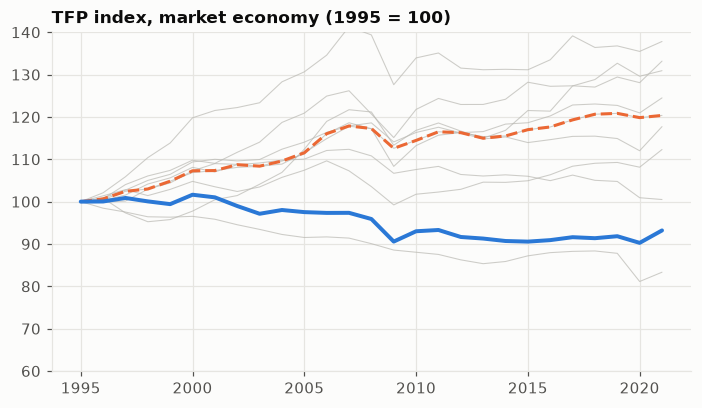

In [4]:
# TFP level index (1995 = 100), market economy
t = ek[(ek.nace_r2_code == "MARKT") & (ek.variable == "LP1TFP_I")].pivot(index="year", columns="iso3", values="value"); t = t / t.loc[1995] * 100
fig, ax = plt.subplots(figsize=(7.5, 4)); oth = t[[c for c in t if c in EU27_ISO3 and c != ITALY]]
for c in oth: ax.plot(oth.index, oth[c], color=PEER_C, lw=0.7, alpha=0.7)
ax.plot(oth.index, oth.median(axis=1), color=EU_C, lw=2, ls="--"); ax.plot(t.index, t[ITALY], color=ITALY_C, lw=2.6); ax.set_ylim(60, 140); ax.set_title("TFP index, market economy (1995 = 100)"); save(fig, "23_tfp_index")
print("TFP 1995-2019: Italy %.0f | DEU %.0f | FRA %.0f | ESP %.0f | median of others %.0f" % (t.loc[2019, ITALY], t.loc[2019, "DEU"], t.loc[2019, "FRA"], t.loc[2019, "ESP"], oth.loc[2019].median()))

## Takeaways (EU KLEMS & INTANProd, release 2025; market economy; pp per year unless stated)
- **The shortfall is TFP, not capital or skills.** Labour productivity per hour grew 0.60% a year in 1996-2019 in Italy (Germany 1.45%, France 1.32%, Spain 0.57%; the median of the other members is higher because it includes fast-converging eastern economies: 2.35%). Italy's contribution from total factor productivity was -0.36 (Germany +0.85, France +0.19, Spain -0.54, median of the others +0.79), while labour composition (+0.36, median +0.36), ICT capital (+0.04 vs +0.02), other tangible capital (+0.30 vs +0.22) and intangible capital (+0.25 vs +0.35) are close to the median. TFP in the market economy is 8% *below* its 1995 level in 2019 (Germany +23%, France +5%, Spain -12%).
- **Two phases.** Before 2008 Italy's TFP contribution was -0.22 a year while Germany's was +1.42, France's +0.97 and the median's +1.37; after 2008 it was -0.49 (Germany +0.28, France -0.58, Spain -0.33, median +0.21). So Italy's weakness predates the crisis, while after 2008 France and Spain also had negative TFP contributions and the gap to the median narrowed.
- **By industry (1996-2019, 13-15 countries with industry accounts).** TFP contributions are most negative in utilities and waste (-3.8 vs a median of -1.1), construction (-2.0 vs -0.2), professional and administrative services (-1.3 vs -0.1). The largest gap is in manufacturing: -0.43 in Italy against +1.55 for the median (about 2 points a year), followed by agriculture (+0.37 vs +1.63) and information and communication (+0.34 vs +1.15). Finance (+0.85 vs +0.28) and mining are exceptions. This complements notebook 13: both show weakness in construction and professional services, while the manufacturing gap is clearer in TFP terms than in output per hour.
- **Caveats:** TFP is a residual that absorbs mismeasurement (capital utilisation, services quality, firm composition); industry accounts exist for fewer countries than the market-economy aggregate; the 'median of the other members' includes catching-up economies. The data cannot say whether the TFP shortfall reflects firm size, regulation or allocation (see the literature notes: Hsieh-Klenow 2009; Gopinath et al. 2017), which needs firm-level data.